# What's It Good For?
### A machine-learning sorter that turns a material's numbers into a likely role

**Author:** James Fox · Energy Materials Informatics, Project 05 · Fall 2026

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jamesfox2008-hue/energy-materials-informatics/blob/main/05-whats-it-good-for/whats_it_good_for.ipynb)

Projects 01 and 03 each asked one yes/no question about a material: is it stable enough, is its gap narrow enough. This notebook asks the broader question a tech-transfer office or a new lab member asks first: **given a material, what is it likely to be good for?**

The answer here rests on one number that decides most of a material's electronic jobs: its **band gap**, the energy an electron needs to start conducting. Metals have none. A narrow gap suits thermoelectrics and infrared detectors; a gap near 1.3 eV suits solar cells; a wide gap makes an insulator, which is what a battery's solid electrolyte must be.

The algorithm uses the best numbers available, in three tiers:

| You have | The sorter uses | Section |
|---|---|---|
| A measured band gap | A plain rule: which window the gap falls in | 2 |
| Only the formula | 132 numbers computed from the elements, and a random forest trained on about 4,800 measured compounds | 6 |
| The formula plus a calculated gap from the Materials Project | The same 132 numbers plus 3 calculated-gap numbers | 8 |

## 1. Setup

In [ ]:
# matminer (composition features, brings pymatgen) isn't preinstalled in Colab
%pip install -q matminer

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [ ]:
import os, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pymatgen.core import Composition
from matminer.featurizers.composition import ElementProperty
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

# Same chart style as Projects 01 and 03
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, GRAY, LIGHT_ORANGE = "#2a78d6", "#eb6834", "#b5b3ab", "#f7c9b5"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 11, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

def save(fig, name):
    fig.savefig(f"figures/{name}.png")
    plt.show()

def paired_bars(ax, labels, a, b, label_a, label_b, color_b=BLUE):
    # Two horizontal bars per row (grey = comparison, colour = this notebook's method), value at each tip
    yy = np.arange(len(labels))[::-1]
    ax.barh(yy + 0.18, a, height=0.36, color=GRAY, label=label_a)
    ax.barh(yy - 0.18, b, height=0.36, color=color_b, label=label_b)
    for yi, va, vb in zip(yy, a, b):
        ax.text(va + 0.01, yi + 0.18, f"{va:.0%}", va="center", fontsize=9, color=INK_2)
        ax.text(vb + 0.01, yi - 0.18, f"{vb:.0%}", va="center", fontsize=9, color=color_b)
    ax.set_yticks(yy, labels)
    ax.set_xlim(0, 1.45)
    ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="y", visible=False)
    ax.legend(frameon=False, loc="center right", fontsize=9)

## 2. The six purpose classes

Each class is a band-gap window with a physical reason for its edges. A gap of *E* electron-volts lets a material absorb light out to a wavelength of about 1240 / *E* nanometers, so several edges come straight from wavelengths that matter.

| Class | Band gap | Typical jobs | Why the edge sits there |
|---|---|---|---|
| **Conductor** | none (metal) | wires, contacts, current collectors, electrode additives | no gap at all |
| **Thermoelectric / SWIR** | ≤ 0.73 eV | heat-to-power and Peltier cooling; infrared detectors out to 1700 nm | 1240 / 1700 nm = 0.73 eV, the end of the short-wave infrared band (Project 03) |
| **Near-IR / bottom cell** | 0.73–1.13 eV | near-infrared detectors, bottom cells of tandem solar panels | 1.13 eV is silicon's own absorption edge (1100 nm) |
| **Solar absorber** | 1.13–1.8 eV | single-junction solar cells, tandem top cells | the Shockley–Queisser efficiency peak is at 1.34 eV; tandem top cells sit near 1.7 eV |
| **Visible light** | 1.8–3.1 eV | LEDs, photocatalysts (water splitting needs at least 1.23 eV plus losses), wide-gap top cells | 3.1 eV is the violet end of visible light (400 nm) |
| **Wide gap / insulator** | > 3.1 eV | UV devices, dielectrics, transparent hosts, solid-electrolyte candidates | transparent to visible light; electrons can't cross easily |

**Where energy storage fits.** A battery's electrolyte must carry ions but block electrons, so a solid electrolyte has to be a wide-gap insulator. A wide gap is necessary but not enough: it also needs fast ion conduction, which this model does not see. Electrodes are the opposite case and need electrons to move, which is why poorly conducting cathodes are coated with carbon.

In [ ]:
EDGES = [0.73, 1.13, 1.8, 3.1]    # eV; a gap exactly on an edge goes to the lower class
CLASSES = ["Conductor", "Thermoelectric / SWIR", "Near-IR / bottom cell",
           "Solar absorber", "Visible light", "Wide gap / insulator"]
SHORT = ["Conductor", "Thermo/SWIR", "Near-IR", "Solar", "Visible", "Wide gap"]
USES = ["wires, contacts, current collectors",
        "thermoelectrics, infrared detectors to 1700 nm",
        "near-infrared detectors, tandem bottom cells",
        "single-junction solar cells, tandem top cells",
        "LEDs, photocatalysts, wide-gap top cells",
        "UV devices, dielectrics, solid-electrolyte candidates"]

def gap_to_class(gap_eV):
    # Tier 0, the plain rule: 0 = metal, then one class per window
    if gap_eV <= 0:
        return 0
    return 1 + int(np.searchsorted(EDGES, gap_eV, side="left"))

## 3. Get the data

All three files download from fixed versions, so the results reproduce. They are the same sources Project 03 used.

| Data | What it holds | Source |
|---|---|---|
| Measured band gaps | 3,895 measurements of 2,470 non-metallic compounds, collected from the literature | Zhuo, Mansouri Tehrani & Brgoch (2018), as packaged in the Roost repository |
| Metal or not | 4,921 compounds labeled metal or non-metal | Same source, as packaged by Matbench |
| Calculated band gaps | 106,113 computed (DFT) entries from the Materials Project | Matbench `mp_gap`, via the CrabNet repository |

In [ ]:
ROOST = "https://raw.githubusercontent.com/CompRhys/roost/aaabc34d6ee6ac788e36f1c759c0582a997ea9b9/data/datasets/roost/"
CRABNET = "https://raw.githubusercontent.com/anthony-wang/CrabNet/457b4d4835737ecbe4dd33e53174bd818bd82143/data/matbench/"

def fetch(url, name):
    path = os.path.join("data", name)
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)
    return path

reduced = lambda f: Composition(f).reduced_formula     # 'Ga1As1' and 'GaAs' become the same formula
elements = lambda f: {e.symbol for e in Composition(f).elements}

meas = pd.read_csv(fetch(ROOST + "expt-non-metals.csv", "zhuo_nonmetals.csv"))
meas["formula"] = meas["composition"].map(reduced)
gaps = meas.groupby("formula")["Eg"].median()          # several reports per compound: use the median

metal = pd.read_csv(fetch(CRABNET + "expt_is_metal.csv", "matbench_expt_is_metal.csv"))
metal["formula"] = metal["formula"].map(reduced)
metal = metal.groupby("formula")["target"].max()       # 1 = metal
metals = sorted(set(metal[metal == 1].index) - set(gaps.index))   # drop any formula labeled both ways

mp = pd.read_csv(fetch(CRABNET + "mp_gap.csv", "matbench_mp_gap.csv"))
mp["formula"] = mp["formula"].map(reduced)
# A formula can have several calculated structures (polymorphs): keep the lowest, typical and highest gap
dft = mp.groupby("formula")["target"].agg(dft_gap_min="min", dft_gap_median="median", dft_gap_max="max")
DFT_COLS = list(dft.columns)

data = pd.concat([pd.DataFrame({"gap_eV": 0.0}, index=metals),
                  pd.DataFrame({"gap_eV": gaps.values}, index=gaps.index)])
data["label"] = [gap_to_class(g) for g in data["gap_eV"]]
data = data.join(dft)
print(f"{len(data):,} compounds: {len(metals):,} labeled metal and {len(gaps):,} measured non-metals · "
      f"{data['dft_gap_median'].notna().sum():,} also have a calculated gap")

4,920 compounds: 2,450 labeled metal and 2,470 measured non-metals · 3,613 also have a calculated gap


## 4. Audit the labels first

Before training anything, check whether the labels make chemical sense. The "metal" list turns out to include compounds any chemist would call insulators.

**The check.** Density functional theory (DFT), the method behind the Materials Project, usually *under*estimates band gaps. So if even a DFT calculation finds a gap above 0.5 eV for some structure of a compound, a "metal" label for it is very unlikely to be right. Those labels are dropped.

In [ ]:
suspect = (data["label"] == 0) & (data["dft_gap_max"] > 0.5)
oxide_like = data.index.map(lambda f: bool(elements(f) & {"O", "F", "Cl"}))
print(f"{suspect.sum()} of {len(metals):,} 'metal' labels contradicted by a calculated gap above 0.5 eV "
      f"({suspect[oxide_like].sum()} of them oxides, fluorides or chlorides)")
print(f"'Metal' labels on compounds containing O, F or Cl: {((data['label'] == 0) & oxide_like).sum()} of {len(metals):,}")
data.loc[suspect].sort_values("dft_gap_max", ascending=False).head(10)[["dft_gap_min", "dft_gap_max"]].round(2)

101 of 2,450 'metal' labels contradicted by a calculated gap above 0.5 eV (87 of them oxides, fluorides or chlorides)
'Metal' labels on compounds containing O, F or Cl: 674 of 2,450


,dft_gap_min,dft_gap_max
P2O5,4.84,5.54
Na2SO4,4.96,5.03
P2H12N7Cl,4.95,4.95
Y2Ge2O7,2.95,3.90
Li4WO5,3.05,3.89
Li2Ni5(PO4)4,3.54,3.54
SrNi2(PO4)2,3.53,3.53
NdGaO3,3.45,3.45
NdO2,0.00,3.41
AgCNO,3.05,3.05


Sodium sulfate, phosphorus pentoxide and nickel phosphates are textbook insulators, yet the benchmark lists them as metals. The calculated-gap check catches only the ones the Materials Project covers, so other bad labels remain, and the model in section 6 inherits them. That matters most for transition-metal oxides (section 7).

Interestingly, the same check confirms that real metallic oxides keep their label: ReO₃, RuO₂, SrRuO₃ and LaNiO₃ all have calculated gaps of zero.

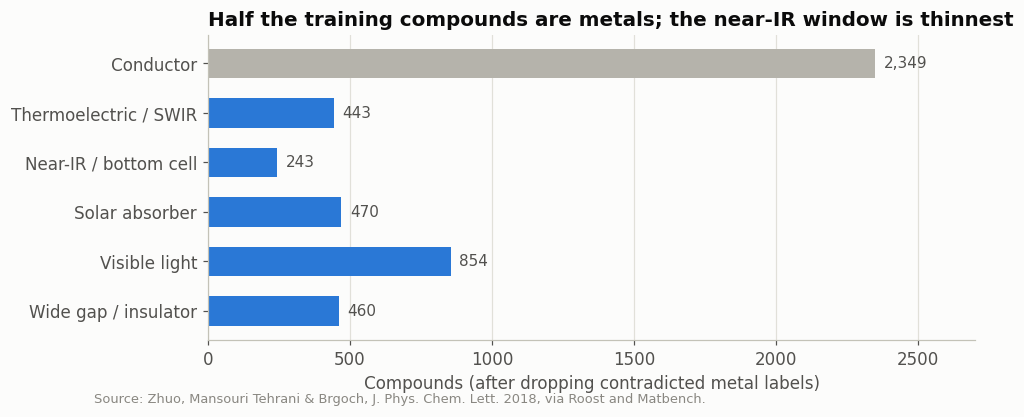

In [ ]:
data = data[~suspect].copy()
counts = data["label"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.6))
yy = np.arange(len(CLASSES))[::-1]
ax.barh(yy, counts.values, height=0.6, color=[GRAY] + [BLUE] * 5)
for yi, v in zip(yy, counts.values):
    ax.text(v + 30, yi, f"{v:,}", va="center", fontsize=10, color=INK_2)
ax.set_yticks(yy, CLASSES)
ax.set_xlim(0, counts.max() * 1.15)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Compounds (after dropping contradicted metal labels)")
ax.set_title("Half the training compounds are metals; the near-IR window is thinnest")
fig.text(0.01, -0.05, "Source: Zhuo, Mansouri Tehrani & Brgoch, J. Phys. Chem. Lett. 2018, via Roost and Matbench.",
         fontsize=8.5, color=MUTED)
save(fig, "01_class_counts")

The classes are uneven. Half the compounds are metals, and the near-IR window (only 0.4 eV wide) has the fewest examples. A model that always said "Conductor" would already be right half the time, so that is the baseline to beat. The model is trained with each class weighted equally so the small classes count.

## 5. Turn each formula into numbers

Each formula becomes 132 numbers using the standard **Magpie** recipe (Ward *et al.*, 2016). For 22 properties of the elements, such as electronegativity, atomic radius, number of valence electrons, and each element's own band gap, it records six summaries across the formula, weighted by composition: the mean, minimum, maximum, range, mode and average deviation.

For GaAs, for example, the mean electronegativity is the average of gallium's and arsenic's, and the range is the difference between them, which hints at how ionic the bonds are. No crystal structure is used, which is what lets the model score formulas nobody has made yet.

**Sixteen well-known compounds are held out** from all training and used as a final test in section 9.

In [ ]:
ep = ElementProperty.from_preset("magpie")
def featurize(formulas):
    X = np.array([ep.featurize(Composition(f)) for f in formulas], dtype=float)
    return pd.DataFrame(X, index=list(formulas), columns=ep.feature_labels())

HOLDOUT = [reduced(f) for f in ["InAs", "Bi2Te3", "SnSe", "CuInSe2", "GaAs", "CdTe", "MnO2", "Fe2O3",
                                "WO3", "TiO2", "GaN", "SrTiO3", "Li3PS4", "LiI", "LiF", "NiO"]]
F = featurize(data.index)
FILL = F.median()
F = F.fillna(FILL)

train = data[~data.index.isin(HOLDOUT)]
X, y = F.loc[train.index].values, train["label"].values
print(f"{F.shape[1]} numbers per formula · training on {len(y):,} compounds · {len(HOLDOUT)} held out")
F.loc[["GaAs"], [c for c in F.columns if "Electronegativity" in c]].round(2)

132 numbers per formula · training on 4,803 compounds · 16 held out


,MagpieData minimum Electronegativity,MagpieData maximum Electronegativity,MagpieData range Electronegativity,MagpieData mean Electronegativity,MagpieData avg_dev Electronegativity,MagpieData mode Electronegativity
GaAs,1.81,2.18,0.37,2.0,0.19,1.81


## 6. Tier 1: sorting from the formula alone

**The model.** A random forest: 500 decision trees, each trained on a random sample of the compounds and a random subset of the 132 numbers. Each tree asks a chain of yes/no questions ("is the mean electronegativity above 1.9?"), and the forest takes a vote. The share of votes is the model's **confidence**.

**The test.** Five-fold cross-validation: the compounds are split into five groups, and each group is predicted by a model trained only on the other four. Every compound gets a prediction from a model that never saw it.

**Two comparisons:**
1. **Always guess "Conductor."** The floor any model must clear.
2. **Predict the number, then sort it.** A metal-or-not classifier plus a band-gap regression, with the predicted gap dropped into the windows. This is the obvious approach, and Project 03 found it hedges toward the middle.

In [ ]:
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
make_forest = lambda: RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE,
                                             class_weight="balanced_subsample", min_samples_leaf=2)
proba_cv = cross_val_predict(make_forest(), X, y, cv=skf, method="predict_proba")
pred_cv = proba_cv.argmax(axis=1)
conf_cv = proba_cv.max(axis=1)

guess_cv = cross_val_predict(DummyClassifier(strategy="most_frequent"), X, y, cv=skf)

# Predict-the-number-then-sort: metal classifier + gap regression trained on non-metals only
gap_train = train["gap_eV"].values
p_metal = cross_val_predict(RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE),
                            X, (y == 0).astype(int), cv=skf, method="predict_proba")[:, 1]
gap_pred = np.zeros(len(y))
for trn, tst in skf.split(X, y):
    keep = trn[y[trn] > 0]
    reg = RandomForestRegressor(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE).fit(X[keep], gap_train[keep])
    gap_pred[tst] = reg.predict(X[tst])
two_step_cv = np.array([0 if pm >= 0.5 else gap_to_class(max(g, 1e-6)) for pm, g in zip(p_metal, gap_pred)])

def scores(truth, pred):
    return {"exact": accuracy_score(truth, pred),
            "within_one_class": np.mean(np.abs(pred - truth) <= 1),
            "balanced": balanced_accuracy_score(truth, pred),
            "macro_F1": f1_score(truth, pred, average="macro")}
results = pd.DataFrame({"Always 'Conductor'": scores(y, guess_cv),
                        "Predict gap, then sort": scores(y, two_step_cv),
                        "Purpose sorter (tier 1)": scores(y, pred_cv)}).T
results.round(3)

,exact,within_one_class,balanced,macro_F1
Always 'Conductor',0.489,0.581,0.167,0.109
"Predict gap, then sort",0.769,0.911,0.645,0.650
Purpose sorter (tier 1),0.778,0.904,0.659,0.665


How to read the four scores:
- **exact**: share of compounds put in exactly the right class.
- **within one class**: right class or a neighboring window. Most mistakes land next door, because a gap measured at 1.10 eV and one at 1.16 eV are nearly the same material but fall on either side of an edge.
- **balanced**: the average of the six per-class hit rates, so the small classes count as much as the metals. Guessing "Conductor" scores only 1 in 6 here.
- **macro F1**: the same idea, but it also penalizes false alarms.

In [ ]:
per_class = pd.DataFrame({
    "compounds": np.bincount(y),
    "found (recall)": recall_score(y, pred_cv, average=None),
    "right when flagged (precision)": precision_score(y, pred_cv, average=None),
    "found by predict-then-sort": recall_score(y, two_step_cv, average=None),
}, index=CLASSES)
per_class.round(2)

,compounds,found (recall),right when flagged (precision),found by predict-then-sort
Conductor,2349,0.91,0.91,0.91
Thermoelectric / SWIR,441,0.68,0.72,0.52
Near-IR / bottom cell,241,0.38,0.47,0.42
Solar absorber,467,0.51,0.53,0.56
Visible light,852,0.74,0.68,0.77
Wide gap / insulator,453,0.74,0.72,0.69


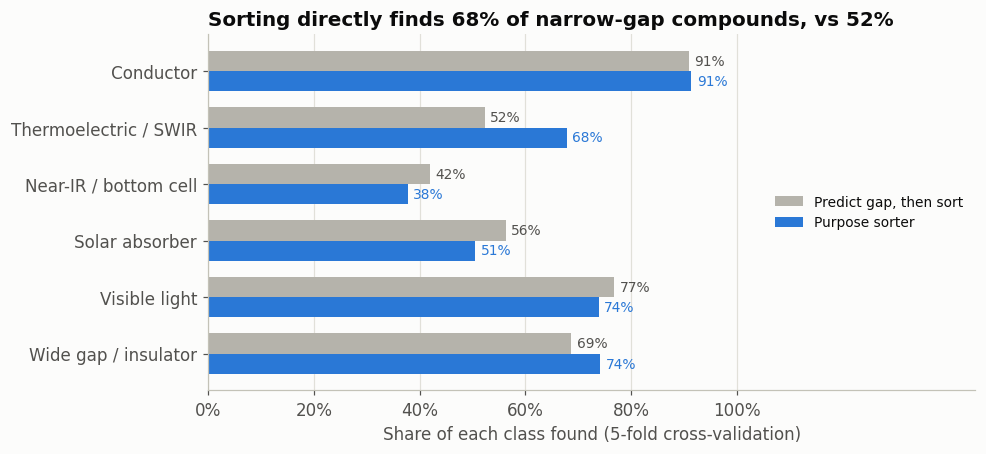

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.2))
paired_bars(ax, CLASSES, per_class["found by predict-then-sort"], per_class["found (recall)"],
            "Predict gap, then sort", "Purpose sorter")
ax.set_xlabel("Share of each class found (5-fold cross-validation)")
nar = per_class.loc["Thermoelectric / SWIR"]
ax.set_title(f"Sorting directly finds {nar['found (recall)']:.0%} of narrow-gap compounds, vs "
             f"{nar['found by predict-then-sort']:.0%}")
save(fig, "02_recall_by_class")

Asking the sorting question directly beats predicting the number first where it matters most for Projects 03 and 04: the narrow-gap compounds. That repeats Project 03's lesson, now across six classes. The trade is a few points in the middle windows, where predict-then-sort does slightly better. The two middle windows are the hardest for both approaches. They are narrow (0.4 and 0.67 eV wide), and repeated measurements of the same compound often disagree by about that much (Project 03 found a median spread of 0.18 eV).

### Where the mistakes go

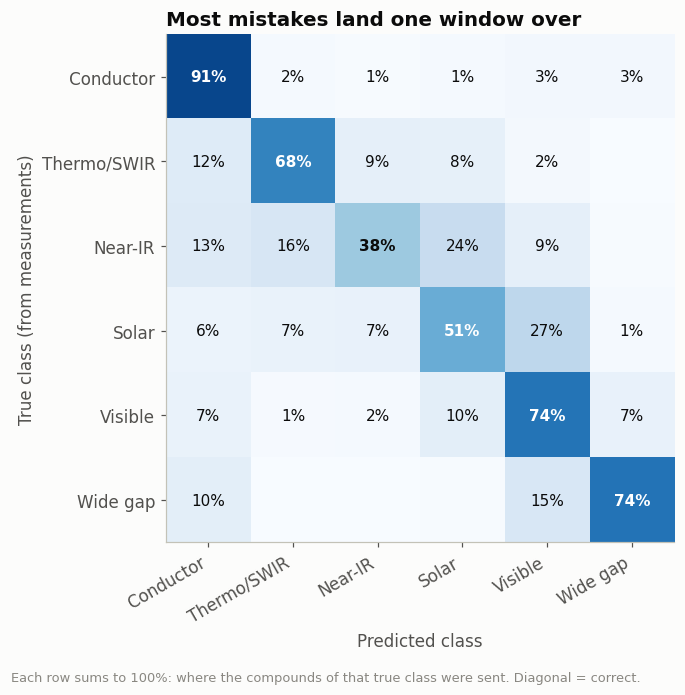

In [ ]:
def confusion_plot(truth, pred, name, title):
    share = confusion_matrix(truth, pred, labels=range(6), normalize="true")
    fig, ax = plt.subplots(figsize=(7.4, 6))
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for i in range(6):
        for j in range(6):
            if share[i, j] >= 0.005:
                ax.text(j, i, f"{share[i, j]:.0%}", ha="center", va="center", fontsize=10,
                        color="white" if share[i, j] > 0.5 else INK, fontweight="bold" if i == j else "normal")
    ax.set_xticks(range(6), SHORT, rotation=30, ha="right")
    ax.set_yticks(range(6), SHORT)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class (from measurements)")
    ax.grid(False)
    ax.set_title(title)
    fig.text(0.01, -0.1, "Each row sums to 100%: where the compounds of that true class were sent. Diagonal = correct.",
             fontsize=8.5, color=MUTED)
    save(fig, name)
confusion_plot(y, pred_cv, "03_where_mistakes_go", "Most mistakes land one window over")

Read across a row. Of the true solar absorbers, about half are called solar, and most of the rest go to a neighbor (near-IR or visible). The other pattern is the first column: a slice of every non-metal class gets called "Conductor." Section 7 shows where those come from.

### When to trust a call

In [ ]:
bands = [(0.0, 0.5), (0.5, 0.7), (0.7, 0.9), (0.9, 1.01)]
trust = pd.DataFrame([{
    "confidence": f"{lo:.0%}–{min(hi, 1):.0%}",
    "share of calls": np.mean((conf_cv >= lo) & (conf_cv < hi)),
    "exact accuracy": accuracy_score(y[(conf_cv >= lo) & (conf_cv < hi)], pred_cv[(conf_cv >= lo) & (conf_cv < hi)]),
} for lo, hi in bands]).set_index("confidence")
high = conf_cv >= 0.7
print(f"Calls at 70%+ confidence: {high.mean():.0%} of compounds, {accuracy_score(y[high], pred_cv[high]):.0%} correct. "
      f"Below 50%: {accuracy_score(y[conf_cv < 0.5], pred_cv[conf_cv < 0.5]):.0%} correct.")
trust.round(2)

Calls at 70%+ confidence: 50% of compounds, 96% correct. Below 50%: 47% correct.


,share of calls,exact accuracy
confidence,,
0%–50%,0.24,0.47
50%–70%,0.26,0.71
70%–90%,0.22,0.92
90%–100%,0.28,0.99


The confidence score means something: high-confidence calls are usually right, and low-confidence calls are close to a coin flip between neighbors. In practice, a low-confidence call is a cue to check the runner-up class too.

## 7. The blind spot: transition-metal oxides

Transition metals (Ti, Mn, Fe, Co, Ni, W and their neighbors) can lose different numbers of electrons. TiO₂, where titanium has given up all four of its outer electrons, is an insulator. Reduced titanium oxides such as Ti₄O₇, with electrons left over, conduct. The formula's element averages barely change between the two, so a formula-only model has a hard time telling them apart, and mislabeled "metals" in the training data make it worse.

Most battery cathodes are transition-metal oxides or phosphates, so this blind spot sits right on top of energy storage.

In [ ]:
TM = {"Ti", "V", "Cr", "Mn", "Fe", "Co", "Ni", "Cu", "Zr", "Nb", "Mo", "Ru", "Rh", "Hf", "Ta", "W", "Re", "Os", "Ir"}
is_tm_oxide = np.array([bool(elements(f) & TM) and "O" in elements(f) for f in train.index])
nonmetal = y > 0
called_metal = lambda pred, mask: np.mean(pred[mask & nonmetal] == 0)
blind = {
    "TM-oxide non-metals called 'Conductor'": called_metal(pred_cv, is_tm_oxide),
    "other non-metals called 'Conductor'": called_metal(pred_cv, ~is_tm_oxide),
}
print(f"{(is_tm_oxide & nonmetal).sum()} measured non-metallic transition-metal oxides in training")
pd.Series(blind).round(3)

215 measured non-metallic transition-metal oxides in training


,0
TM-oxide non-metals called 'Conductor',0.279
other non-metals called 'Conductor',0.071


The formula-only model calls a much larger share of insulating transition-metal oxides "Conductor" than it does other non-metals. More features from the formula alone would not fix this. Electron-counting features based on guessed oxidation states were tried during development and moved the scores by less than a point. What helps is a number that knows about electrons in an actual crystal: a calculated band gap.

## 8. Tier 2: add a calculated band gap

The Materials Project has run DFT calculations on more than 100,000 compounds. DFT tends to underestimate gaps, often by a lot, so its gap can't simply replace a measurement. But as three extra numbers next to the 132 (the lowest, typical and highest gap across a formula's calculated structures), it tells the model whether electrons in a real crystal are free or bound.

**A fair comparison.** Only compounds the Materials Project covers can use tier 2, and they differ from the rest. So both tiers are retrained and scored on exactly the same compounds.

In [ ]:
covered = train["dft_gap_median"].notna().values
Xc, yc = X[covered], y[covered]
Xc2 = np.hstack([Xc, train.loc[covered, DFT_COLS].values])
p1 = cross_val_predict(make_forest(), Xc, yc, cv=skf, method="predict_proba")
p2 = cross_val_predict(make_forest(), Xc2, yc, cv=skf, method="predict_proba")
t1, t2 = p1.argmax(axis=1), p2.argmax(axis=1)
tiers = pd.DataFrame({"Tier 1: formula only": scores(yc, t1),
                      "Tier 2: formula + calculated gap": scores(yc, t2)}).T
tm_c, nm_c = is_tm_oxide[covered], yc > 0
tiers["TM-oxide non-metals called 'Conductor'"] = [np.mean(t[tm_c & nm_c] == 0) for t in (t1, t2)]
print(f"Scored on the {covered.sum():,} training compounds that have a calculated gap")
tiers.round(3)

Scored on the 3,496 training compounds that have a calculated gap


,exact,within_one_class,balanced,macro_F1,TM-oxide non-metals called 'Conductor'
Tier 1: formula only,0.783,0.901,0.584,0.590,0.352
Tier 2: formula + calculated gap,0.835,0.944,0.619,0.633,0.124


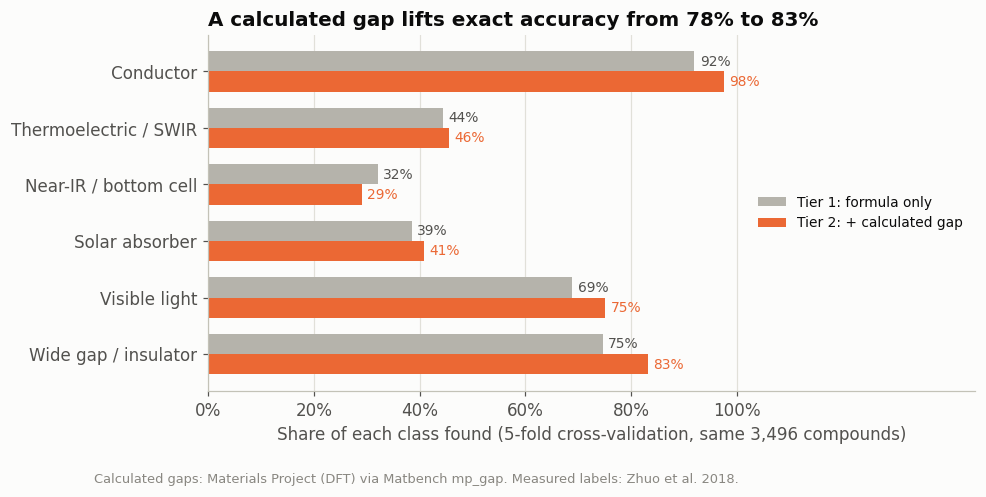

,tier 1,tier 2
Conductor,0.92,0.98
Thermoelectric / SWIR,0.44,0.46
Near-IR / bottom cell,0.32,0.29
Solar absorber,0.39,0.41
Visible light,0.69,0.75
Wide gap / insulator,0.75,0.83


In [ ]:
tier_recall = pd.DataFrame({"tier 1": recall_score(yc, t1, average=None),
                            "tier 2": recall_score(yc, t2, average=None)}, index=CLASSES)
fig, ax = plt.subplots(figsize=(9, 4.2))
paired_bars(ax, CLASSES, tier_recall["tier 1"], tier_recall["tier 2"],
            "Tier 1: formula only", "Tier 2: + calculated gap", color_b=ORANGE)
ax.set_xlabel(f"Share of each class found (5-fold cross-validation, same {covered.sum():,} compounds)")
ax.set_title(f"A calculated gap lifts exact accuracy from {tiers.iloc[0]['exact']:.0%} to {tiers.iloc[1]['exact']:.0%}")
fig.text(0.01, -0.09, "Calculated gaps: Materials Project (DFT) via Matbench mp_gap. Measured labels: Zhuo et al. 2018.",
         fontsize=8.5, color=MUTED)
save(fig, "04_tier2_recall")
tier_recall.round(2)

The calculated gap mainly sharpens the two ends: telling metals from insulators, and spotting wide-gap compounds. It helps less in the middle windows, where DFT's underestimate blurs exactly the distinctions that matter. Both tiers keep their place: tier 1 works on any formula, even one nobody has made; tier 2 is more reliable when a calculation exists.

## 9. What the model looks at

A random forest records how much each number helped split the compounds. Grouping the six summaries of each element property shows which chemistry the formula-only model leans on.

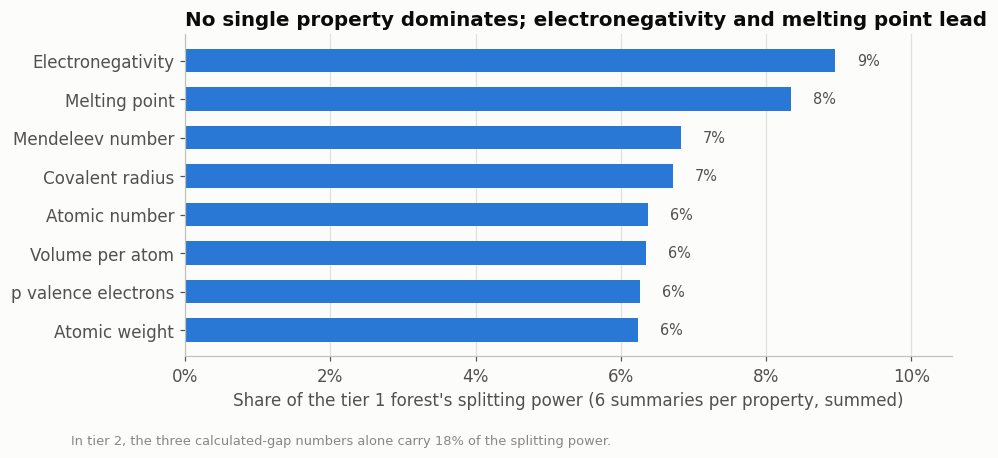

Tier 2: calculated-gap numbers carry 18% of the splitting power


,0
Electronegativity,0.090
Melting point,0.083
Mendeleev number,0.068
Covalent radius,0.067
Atomic number,0.064
Volume per atom,0.064
p valence electrons,0.063
Atomic weight,0.062


In [ ]:
sorter = make_forest().fit(X, y)                                       # tier 1, all training compounds
cov_all = train["dft_gap_median"].notna().values
sorter2 = make_forest().fit(np.hstack([X[cov_all], train.loc[cov_all, DFT_COLS].values]), y[cov_all])   # tier 2

PLAIN = {"GSbandgap": "Elements' own band gaps", "Electronegativity": "Electronegativity",
         "NpValence": "p valence electrons", "NdValence": "d valence electrons", "NValence": "Valence electrons",
         "NUnfilled": "Unfilled orbitals", "NdUnfilled": "Unfilled d orbitals", "NpUnfilled": "Unfilled p orbitals",
         "NsUnfilled": "Unfilled s orbitals", "NsValence": "s valence electrons", "NfValence": "f valence electrons",
         "NfUnfilled": "Unfilled f orbitals", "Column": "Periodic-table column", "Row": "Periodic-table row",
         "MendeleevNumber": "Mendeleev number", "Number": "Atomic number", "AtomicWeight": "Atomic weight",
         "MeltingT": "Melting point", "CovalentRadius": "Covalent radius", "GSvolume_pa": "Volume per atom",
         "GSmagmom": "Magnetic moment", "SpaceGroupNumber": "Elements' crystal symmetry"}
prop = [c.split(" ", 2)[2] for c in F.columns]
importance = pd.Series(sorter.feature_importances_, index=prop).groupby(level=0).sum().sort_values(ascending=False)
importance.index = [PLAIN.get(p, p) for p in importance.index]
dft_share = sorter2.feature_importances_[-3:].sum()
top = importance.head(8)
fig, ax = plt.subplots(figsize=(9, 3.8))
yy = np.arange(len(top))[::-1]
ax.barh(yy, top.values, height=0.6, color=BLUE)
for yi, v in zip(yy, top.values):
    ax.text(v + 0.003, yi, f"{v:.0%}", va="center", fontsize=9.5, color=INK_2)
ax.set_yticks(yy, top.index)
ax.set_xlim(0, top.max() * 1.18)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of the tier 1 forest's splitting power (6 summaries per property, summed)")
ax.set_title(f"No single property dominates; {top.index[0].lower()} and {top.index[1].lower()} lead")
fig.text(0.01, -0.1, f"In tier 2, the three calculated-gap numbers alone carry {dft_share:.0%} of the splitting power.",
         fontsize=8.5, color=MUTED)
save(fig, "05_what_the_model_looks_at")
print(f"Tier 2: calculated-gap numbers carry {dft_share:.0%} of the splitting power")
importance.head(8).round(3)

The formula-only model spreads its attention across many element properties, led by electronegativity, melting point and position in the periodic table. That lines up with textbook chemistry: a big electronegativity difference means ionic bonds, which hold electrons tightly and open the gap. Feature importance shows what the model *uses*, not proof of cause, but it's a useful check that the model isn't keying on something meaningless. In tier 2, the calculated gap takes over a large share of the work, as it should.

## 10. Final test: 16 compounds neither tier ever saw

In [ ]:
def tier2_inputs(formulas, gap_table=None):
    g = (gap_table if gap_table is not None else dft).reindex(formulas)
    return np.hstack([featurize(formulas).fillna(FILL).values, g.values])

test = data.loc[HOLDOUT]
pr1 = sorter.predict_proba(F.loc[HOLDOUT].values)
has2 = test["dft_gap_median"].notna().values
pr2 = np.full_like(pr1, np.nan)
pr2[has2] = sorter2.predict_proba(np.hstack([F.loc[HOLDOUT].values[has2], test.loc[has2, DFT_COLS].values]))
held = pd.DataFrame({
    "measured_gap_eV": test["gap_eV"].values,
    "true_class": [SHORT[k] for k in test["label"]],
    "tier1_call": [SHORT[k] for k in pr1.argmax(axis=1)],
    "tier1_conf": pr1.max(axis=1),
    "tier2_call": [SHORT[k] if h else "n/a" for k, h in zip(np.nan_to_num(pr2).argmax(axis=1), has2)],
    "tier2_conf": np.where(has2, np.nan_to_num(pr2).max(axis=1), np.nan),
}, index=HOLDOUT)
off1 = np.abs(pr1.argmax(axis=1) - test["label"].values)
off2 = np.abs(np.nan_to_num(pr2).argmax(axis=1) - test["label"].values)
hold_scores = {"tier1_exact": int((off1 == 0).sum()), "tier1_within_one": int((off1 <= 1).sum()),
               "tier2_exact": int((off2[has2] == 0).sum()), "tier2_within_one": int((off2[has2] <= 1).sum()),
               "total": len(HOLDOUT), "tier2_total": int(has2.sum())}
print(f"Tier 1: {hold_scores['tier1_exact']} of {len(HOLDOUT)} exact, {hold_scores['tier1_within_one']} within one class · "
      f"Tier 2: {hold_scores['tier2_exact']} of {has2.sum()} exact, {hold_scores['tier2_within_one']} within one class")
held.sort_values("measured_gap_eV").round(2)

Tier 1: 8 of 16 exact, 11 within one class · Tier 2: 9 of 16 exact, 14 within one class


,measured_gap_eV,true_class,tier1_call,tier1_conf,tier2_call,tier2_conf
Bi2Te3,0.25,Thermo/SWIR,Thermo/SWIR,0.98,Thermo/SWIR,0.73
InAs,0.41,Thermo/SWIR,Thermo/SWIR,0.65,Thermo/SWIR,0.50
SnSe,0.94,Near-IR,Thermo/SWIR,0.35,Solar,0.41
InCuSe2,0.95,Near-IR,Near-IR,0.73,Solar,0.48
MnO2,1.30,Solar,Conductor,0.78,Conductor,0.40
GaAs,1.51,Solar,Solar,0.44,Near-IR,0.48
CdTe,1.57,Solar,Solar,0.41,Thermo/SWIR,0.41
Fe2O3,2.20,Visible,Conductor,0.91,Wide gap,0.33
WO3,2.80,Visible,Conductor,0.57,Visible,0.44
SrTiO3,3.28,Wide gap,Wide gap,0.46,Wide gap,0.52


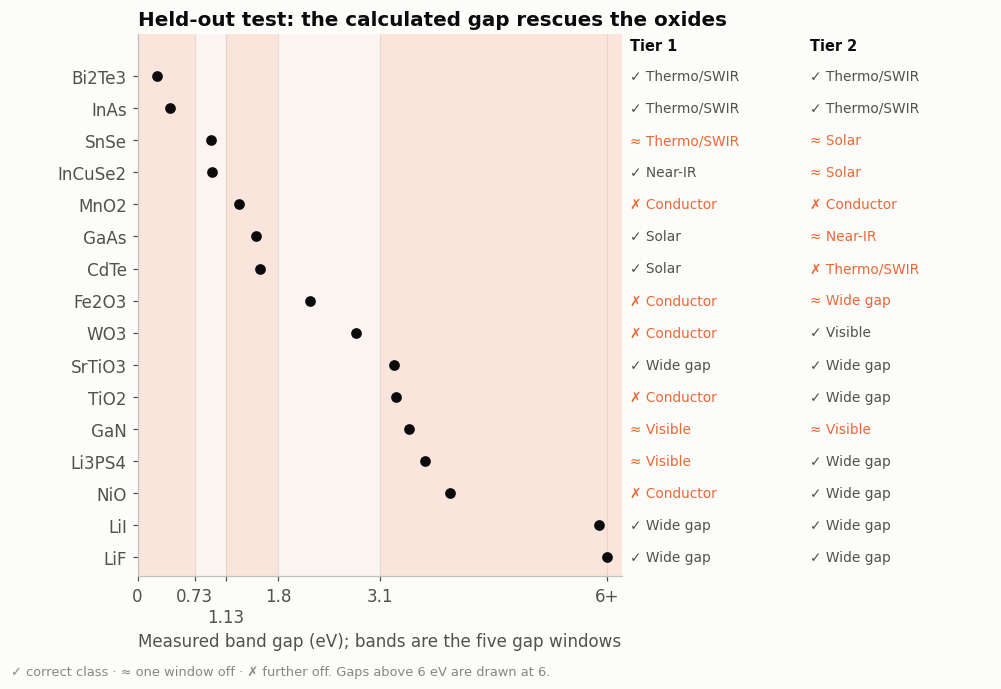

In [ ]:
h = held.sort_values("measured_gap_eV", ascending=False)
fig, ax = plt.subplots(figsize=(10, 6.4))
yy = np.arange(len(h))
for x0, x1, k in zip([0] + EDGES, EDGES + [6.2], range(1, 6)):
    ax.axvspan(x0, x1, color=LIGHT_ORANGE, alpha=0.45 if k % 2 else 0.15, lw=0)
ax.plot(h["measured_gap_eV"].clip(upper=6), yy, "o", color=INK, ms=6)
mark = lambda call, true: "✓" if call == true else ("≈" if abs(SHORT.index(call) - SHORT.index(true)) == 1 else "✗")
for yi, (f, r) in zip(yy, h.iterrows()):
    m1, m2 = mark(r["tier1_call"], r["true_class"]), mark(r["tier2_call"], r["true_class"])
    ax.text(6.3, yi, f"{m1} {r['tier1_call']}", va="center", fontsize=9, color=INK_2 if m1 == "✓" else ORANGE)
    ax.text(8.6, yi, f"{m2} {r['tier2_call']}", va="center", fontsize=9, color=INK_2 if m2 == "✓" else ORANGE)
ax.text(6.3, len(h) - 0.2, "Tier 1", fontsize=9.5, fontweight="bold", color=INK)
ax.text(8.6, len(h) - 0.2, "Tier 2", fontsize=9.5, fontweight="bold", color=INK)
ax.set_yticks(yy, h.index)
ax.set_xlim(0, 10.9)
ax.set_ylim(-0.6, len(h) + 0.3)
ax.set_xticks([0, 0.73, 1.13, 1.8, 3.1, 6], ["0", "0.73", "\n1.13", "1.8", "3.1", "6+"])
ax.spines["bottom"].set_bounds(0, 6.2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Measured band gap (eV); bands are the five gap windows", loc="left")
ax.set_title("Held-out test: the calculated gap rescues the oxides")
fig.text(0.01, -0.03, "✓ correct class · ≈ one window off · ✗ further off. Gaps above 6 eV are drawn at 6.",
         fontsize=8.5, color=MUTED)
save(fig, "06_holdout_test")

## 11. Try it on battery materials

None of these compounds is in the training data, so the model has never seen them or their measured gaps. Band-gap class is not the same as battery role, but it tells you something real about each one's electronic character:
- A **solid electrolyte** (LLZO, Li₃PO₄, LGPS) must block electrons, so it should land in a wide-gap class.
- **Electrode** materials need electrons to move. Several common cathodes are poor electronic conductors on their own, which is why commercial LiFePO₄ is coated with carbon. A wide-gap call for a cathode is a flag for that engineering problem, not a sign the material is useless.

In [ ]:
BATTERY = {"LiCoO2": "cathode", "LiFePO4": "cathode", "LiMn2O4": "cathode", "Li4Ti5O12": "anode",
           "Li2S": "cathode (Li–S, discharged)", "Li7La3Zr2O12": "solid electrolyte (LLZO)",
           "Li3PO4": "solid electrolyte", "Li3N": "solid electrolyte", "Li10GeP2S12": "solid electrolyte (LGPS)"}
names = [reduced(f) for f in BATTERY]
assert not set(names) & set(data.index), "a battery example is in the training data"
q1 = sorter.predict_proba(featurize(names).fillna(FILL).values)
q2 = sorter2.predict_proba(tier2_inputs(names))
battery = pd.DataFrame({
    "role in a battery": list(BATTERY.values()),
    "tier 1 (formula)": [SHORT[k] for k in q1.argmax(axis=1)],
    "tier 1 conf": q1.max(axis=1),
    "calculated gap eV (typical)": dft["dft_gap_median"].reindex(names).values,
    "tier 2 (+ calc. gap)": [SHORT[k] for k in q2.argmax(axis=1)],
    "tier 2 conf": q2.max(axis=1),
}, index=names)
battery.round(2)

,role in a battery,tier 1 (formula),tier 1 conf,calculated gap eV (typical),tier 2 (+ calc. gap),tier 2 conf
LiCoO2,cathode,Conductor,1.00,0.46,Conductor,0.65
LiFePO4,cathode,Conductor,0.97,3.48,Wide gap,0.46
LiMn2O4,cathode,Conductor,1.00,0.17,Conductor,0.87
Li4Ti5O12,anode,Conductor,0.90,2.84,Wide gap,0.71
Li2S,"cathode (Li–S, discharged)",Visible,0.44,3.39,Wide gap,0.45
Li7La3Zr2O12,solid electrolyte (LLZO),Conductor,0.69,4.45,Wide gap,0.82
Li3PO4,solid electrolyte,Wide gap,0.56,5.77,Wide gap,0.88
Li3N,solid electrolyte,Visible,0.35,1.10,Visible,0.35
Li10Ge(PS6)2,solid electrolyte (LGPS),Visible,0.34,2.21,Wide gap,0.45


Formula alone, the model calls every lithium transition-metal oxide a conductor with near-total confidence: the blind spot from section 7 in action. With the calculated gap, LiFePO₄, Li₄Ti₅O₁₂ and LLZO move to the insulating side, which matches their known behavior (LiFePO₄ needs carbon coating; LLZO is a solid electrolyte). LiCoO₂ and LiMn₂O₄ stay "Conductor" because their calculated gaps are small, and both do conduct well enough to work as cathodes without the heavy carbon coating LiFePO₄ needs.

## 12. The algorithm in one function

`whats_it_good_for` uses the best numbers available:
1. A **measured band gap** → the plain rule from section 2. No model needed.
2. Otherwise, if the Materials Project has a **calculated gap** for the formula → tier 2.
3. Otherwise → tier 1, from the **formula alone**.

It returns the class, the typical jobs, and, for model calls, the confidence and runner-up.

In [ ]:
def whats_it_good_for(formula, gap_eV=None):
    f = reduced(formula)
    if gap_eV is not None:                                    # 1. measured gap: the rule decides
        k = gap_to_class(gap_eV)
        return {"formula": formula, "class": CLASSES[k], "typical jobs": USES[k],
                "confidence": None, "runner-up": None, "based on": f"measured gap {gap_eV} eV (rule)"}
    if f in dft.index:                                        # 2. formula + calculated gap
        p, basis = sorter2.predict_proba(tier2_inputs([f]))[0], "formula + calculated gap (tier 2)"
    else:                                                     # 3. formula alone
        p, basis = sorter.predict_proba(featurize([f]).fillna(FILL).values)[0], "formula only (tier 1)"
    best, second = np.argsort(-p)[:2]
    return {"formula": formula, "class": CLASSES[best], "typical jobs": USES[best],
            "confidence": round(float(p[best]), 2), "runner-up": CLASSES[second], "based on": basis}

pd.DataFrame([whats_it_good_for("Ag2Se", gap_eV=0.15),
              whats_it_good_for("Ag2Se"),
              whats_it_good_for("Cs2AgBiBr6"),
              whats_it_good_for("BaZrS3"),
              whats_it_good_for("Li6PS5Cl")]).set_index("formula")

,class,typical jobs,confidence,runner-up,based on
formula,,,,,
Ag2Se,Thermoelectric / SWIR,"thermoelectrics, infrared detectors to 1700 nm",NaN,None,measured gap 0.15 eV (rule)
Ag2Se,Near-IR / bottom cell,"near-infrared detectors, tandem bottom cells",0.30,Thermoelectric / SWIR,formula + calculated gap (tier 2)
Cs2AgBiBr6,Visible light,"LEDs, photocatalysts, wide-gap top cells",0.72,Solar absorber,formula + calculated gap (tier 2)
BaZrS3,Visible light,"LEDs, photocatalysts, wide-gap top cells",0.46,Near-IR / bottom cell,formula + calculated gap (tier 2)
Li6PS5Cl,Wide gap / insulator,"UV devices, dielectrics, solid-electrolyte can...",0.47,Visible light,formula + calculated gap (tier 2)


Ag₂Se shows two paths. With its measured gap of 0.15 eV (Hafiz *et al.*, 2019) the rule puts it in thermoelectric / SWIR, as Project 03 found. From the numbers alone, the model has to guess, and the confidence says how sure it is. The other three come from earlier projects and the PhD reading list: a lead-free double perovskite, a chalcogenide perovskite, and a sulfide solid electrolyte (argyrodite).

## 13. Save the key numbers

In [ ]:
summary = {
    "compounds_after_audit": len(data), "metal_labels_dropped": int(suspect.sum()), "features_per_formula": F.shape[1],
    **{f"tier1_cv_{k}": v for k, v in results.loc["Purpose sorter (tier 1)"].items()},
    **{f"guess_conductor_cv_{k}": v for k, v in results.loc["Always 'Conductor'"].items()},
    **{f"predict_then_sort_cv_{k}": v for k, v in results.loc["Predict gap, then sort"].items()},
    **{f"tier1_recall_{s}": v for s, v in zip(SHORT, per_class["found (recall)"])},
    **{f"predict_then_sort_recall_{s}": v for s, v in zip(SHORT, per_class["found by predict-then-sort"])},
    "tier1_share_of_calls_at_70pct_confidence": high.mean(),
    "tier1_accuracy_at_70pct_confidence": accuracy_score(y[high], pred_cv[high]),
    "tier1_accuracy_below_50pct_confidence": accuracy_score(y[conf_cv < 0.5], pred_cv[conf_cv < 0.5]),
    **{f"blind_spot_{k}": v for k, v in blind.items()},
    "tier_comparison_compounds": int(covered.sum()),
    **{f"same_set_tier1_{k}": v for k, v in tiers.iloc[0].items()},
    **{f"same_set_tier2_{k}": v for k, v in tiers.iloc[1].items()},
    **{f"same_set_tier1_recall_{s}": v for s, v in zip(SHORT, tier_recall["tier 1"])},
    **{f"same_set_tier2_recall_{s}": v for s, v in zip(SHORT, tier_recall["tier 2"])},
    "tier2_share_of_splitting_from_calculated_gap": dft_share,
    **{f"holdout_{k}": v for k, v in hold_scores.items()},
    **{f"importance_{k}": v for k, v in importance.head(3).items()},
}
pd.Series(summary).to_csv("project05_summary.csv", header=["value"])
pd.Series(summary)

,0
compounds_after_audit,4819.000000
metal_labels_dropped,101.000000
features_per_formula,132.000000
tier1_cv_exact,0.778055
tier1_cv_within_one_class,0.904018
...,...
holdout_total,16.000000
holdout_tier2_total,16.000000
importance_Electronegativity,0.089533
importance_Melting point,0.083452


In [ ]:
def predict_use(formula, gap_eV=None):
    f = reduced(formula)
    print(f"\n=== {formula}  (read as {f}) ===")
    if f in data.index:
        print(f"Heads up: this compound was in the training data "
              f"(measured class: {CLASSES[data.loc[f, 'label']]}).")
    if gap_eV is not None:
        k = gap_to_class(gap_eV)
        print(f"Measured gap {gap_eV} eV → {CLASSES[k]}: {USES[k]}  (plain rule, no model)")
        return
    if f in dft.index:
        p = sorter2.predict_proba(tier2_inputs([f]))[0]
        print(f"Using formula + Materials Project calculated gap "
              f"(typical {dft.loc[f, 'dft_gap_median']:.2f} eV, DFT usually runs low)")
    else:
        p = sorter.predict_proba(featurize([f]).fillna(FILL).values)[0]
        print("Using formula only (no calculated gap on file)")
    for k in np.argsort(-p):
        print(f"  {CLASSES[k]:<24}{p[k]:5.0%}  {'█' * int(round(p[k] * 30))}")
    best = int(np.argmax(p))
    print(f"Most likely job: {USES[best]}")
    if p.max() < 0.5:
        print("Low confidence: treat the top two classes as a toss-up.")

while True:
    s = input("Formula (or Enter to stop): ").strip()
    if not s:
        break
    try:
        predict_use(s)
    except Exception as e:
        print(f"Couldn't read '{s}': {e}")

##A box will show up under the cell where you can type formulas such as Li2FeSiO4, Cu2ZnSnS4 or NaCoO2. If you already know a measured gap, call predict_use("Ag2Se", gap_eV=0.15) and it will use the plain rule instead of the model.

##How the prediction is made:

##Formula to numbers. It looks up 22 properties for each element in the formula (electronegativity, atomic radius, valence electron count, and others). For each property it takes six composition-weighted summaries: mean, min, max, range, mode and average deviation. That gives 132 numbers.
##Numbers to class. 500 decision trees each answer a series of yes/no questions, for example “is the mean electronegativity above 1.9?”, and each tree votes for one of the six band-gap classes. The percentage you see next to a class is the share of trees that voted for it.
##Class to use. Each class corresponds to a band-gap window, and each window maps to typical jobs: conductor, thermoelectric/IR, near-IR, solar absorber, visible-light, or wide-gap/insulator.

##Things to keep in mind when reading the output:

##Transition-metal oxides. If the formula is one of these and no calculated gap is on file, a “Conductor” call is unreliable. Section 7 covers this blind spot.
##Structure isn’t considered. The model only sees the composition, so different crystal forms of the same formula get the same answer.
##Band gap is only one factor. It tells you what a material could be considered for, not that it will actually work in that role.




python
import ipywidgets as w
from IPython.display import display

style = {"description_width": "110px"}
formula_box = w.Text(placeholder="e.g. Li2FeSiO4", description="Formula:", style=style)
gap_box = w.Text(placeholder="optional, in eV", description="Measured gap:", style=style)
button = w.Button(description="What's it good for?", button_style="primary")
out = w.Output()

def on_click(_):
    with out:
        out.clear_output()
        s = formula_box.value.strip()
        if not s:
            print("Type a formula first.")
            return
        g = gap_box.value.strip()
        try:
            predict_use(s, float(g) if g else None)
        except Exception as e:
            print(f"Couldn't read '{s}': {e}")

button.on_click(on_click)
display(w.VBox([formula_box, gap_box, button, out]))

## 14. Limits

- **The model sees formulas, not structures.** Polymorphs of the same formula (rutile and anatase TiO₂, or Ag₂Se above and below 133 °C) get the same tier 1 answer.
- **Transition-metal oxides are a blind spot for tier 1.** Use tier 2 or a measured gap for them, which covers most battery cathodes.
- **A band gap is one property among many.** A solar absorber also needs strong absorption and long carrier lifetimes; a thermoelectric needs low thermal conductivity; a solid electrolyte needs fast ion conduction. The sorter says what a material *could* be considered for, not that it will work.
- **The labels inherit the literature's noise.** The audit removed metal labels a calculation contradicts, but compounds the Materials Project doesn't cover went unchecked. Repeated gap measurements of one compound often disagree by around 0.2 eV, a large fraction of the narrow middle windows.
- **Calculated gaps run low.** DFT underestimates most gaps, so tier 2 helps most at the metal–insulator line and least in the middle windows.
- **The class edges are choices.** They follow physical wavelengths, but a compound at 1.12 eV and one at 1.14 eV are not really different materials.

## Sources

- **Measured band gaps:** Zhuo, Y., Mansouri Tehrani, A. & Brgoch, J. Predicting the band gaps of inorganic solids by machine learning. *J. Phys. Chem. Lett.* 9, 1668–1673 (2018). [doi:10.1021/acs.jpclett.8b00124](https://doi.org/10.1021/acs.jpclett.8b00124); copy from the [Roost repository](https://github.com/CompRhys/roost) (MIT license).
- **Metal labels and calculated gaps:** Dunn, A., Wang, Q., Ganose, A., Dopp, D. & Jain, A. Benchmarking materials property prediction methods: the Matbench test set and Automatminer reference algorithm. *npj Comput. Mater.* 6, 138 (2020); via the [CrabNet repository](https://github.com/anthony-wang/CrabNet).
- **Materials Project:** Jain, A. *et al.* Commentary: The Materials Project: A materials genome approach to accelerating materials innovation. *APL Mater.* 1, 011002 (2013). Data CC BY 4.0.
- **Features:** Ward, L., Agrawal, A., Choudhary, A. & Wolverton, C. A general-purpose machine learning framework for predicting properties of inorganic materials. *npj Comput. Mater.* 2, 16028 (2016); computed with [matminer](https://hackingmaterials.lbl.gov/matminer/) and [pymatgen](https://pymatgen.org).
- **Model:** random forest, Breiman, L. *Machine Learning* 45, 5–32 (2001); [scikit-learn](https://scikit-learn.org).
- **Solar-cell efficiency limit:** Shockley, W. & Queisser, H. J. Detailed balance limit of efficiency of p-n junction solar cells. *J. Appl. Phys.* 32, 510 (1961).
- **Ag₂Se bulk gap:** Hafiz, S. B. *et al.* *ACS Appl. Nano Mater.* 2, 1631 (2019).
- **Earlier projects:** [Project 01](../01-perovskite-stability-gap/) and [Project 03](../03-seeing-past-silicon/) in this repository.
